# Red recurrente (GRU / LSTM) sobre la historia mensual - Proyecto HTA (SIS)

**Pregunta del cuaderno:** ¿mejora la predicción si el modelo ve la historia del paciente **mes a mes**, en orden, en lugar de un resumen de dos años?

- **Entrada:** `secuencias_X.npy` (pacientes × 24 meses × 21 variables), `secuencias_estaticas.npy` y `secuencias_meta.csv`, generados por `04_secuencias.ipynb`.
- **Misma cohorte, `y` y partición** que `02_modelos` y `03_random_forest`: el test es exactamente el mismo conjunto de pacientes.

| Sección | Qué responde |
|---|---|
| 1. Cómo funciona | ¿Qué es una GRU y por qué sirve para historias clínicas? |
| 2-3. Datos | Carga y partición |
| 4. Modelos | GRU, LSTM y un **MLP de control** que recibe la misma información sin orden temporal |
| 5. Entrenamiento | Curvas de aprendizaje y *early stopping* |
| 6. Evaluación | ROC-AUC, PR-AUC, Brier, captura del 10% de mayor riesgo |
| 7. ¿Importa el orden? | Bootstrap pareado GRU vs. control, y prueba de meses desordenados |
| 8. ¿Qué meses importan? | Importancia por trimestre |
| 9. Comparación final | Contra la regresión logística y el Random Forest |

## 1. Cómo funciona una red recurrente

Una red recurrente lee la secuencia **un mes a la vez** y mantiene un **estado oculto** $h_t$, un vector que resume lo visto hasta ese mes. En cada paso combina el estado anterior con los datos del mes:

$$h_t = f(h_{t-1},\ x_t)$$

Al llegar a diciembre de 2023, $h_{24}$ resume toda la historia del paciente y se usa para predecir la complicación en 2024.

```
x₁ (ene 22) ─► [GRU] ─► h₁ ─► [GRU] ─► h₂ ─► … ─► [GRU] ─► h₂₄ ──┐
                 ▲              ▲                    ▲            ├─► capa densa ─► P(complicación 2024)
                x₁             x₂                  x₂₄            │
                       edad, sexo, altitud, Lima (estáticas) ─────┘
```

- **GRU** (*Gated Recurrent Unit*, Cho et al., 2014) y **LSTM** (*Long Short-Term Memory*, Hochreiter y Schmidhuber, 1997) agregan **compuertas** que deciden qué recordar y qué olvidar en cada paso. Así evitan que la información de los primeros meses se "borre" en secuencias largas. La GRU tiene menos parámetros que la LSTM y en la práctica suele rendir parecido.
- En la literatura de historias clínicas electrónicas, este enfoque se usó para predecir el inicio de insuficiencia cardíaca (RETAIN, Choi et al., 2016) y eventos cardiovasculares (Zhao et al., 2019).

**El control clave.** Si la GRU supera a la regresión logística, no sabríamos si es por el **orden temporal** o simplemente por ser una red neuronal. Por eso se entrena también un **MLP de control** que recibe exactamente las mismas 21 variables, pero resumidas como **media y máximo de los 24 meses**: la misma información, sin orden. La diferencia GRU − control mide el valor del tiempo.

## 2. Inicializar

In [1]:
try:
    import torch
    from torch import nn
    from torch.utils.data import TensorDataset, DataLoader
except ImportError as e:
    raise ImportError("Falta PyTorch. En la terminal de Anaconda: pip install torch  (versión CPU; ver https://pytorch.org/get-started/locally/)") from e

import copy
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DISPOSITIVO = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(max(1, torch.get_num_threads()))
print("PyTorch", torch.__version__, "| dispositivo:", DISPOSITIVO, "| hilos:", torch.get_num_threads())

AZUL, NARANJA, AQUA, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#e87ba4'
GRIS, TEXTO, TEXTO_2 = '#a3a29b', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ad',
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlecolor': TEXTO, 'axes.labelcolor': TEXTO_2,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'legend.frameon': False,
})

PyTorch 2.15.0+cpu | dispositivo: cpu | hilos: 24


In [2]:
# --- Parámetros ---
HIDDEN = 64              # tamaño del estado oculto de la GRU/LSTM
CAPAS = 1                # capas recurrentes apiladas
DROPOUT = 0.2
LR = 1e-3                # tasa de aprendizaje (Adam)
BATCH = 1024
EPOCAS_MAX = 30
PACIENCIA = 3            # early stopping: épocas sin mejorar el ROC-AUC de validación
ENTRENAR_LSTM = False    # True = también entrena la LSTM (el doble de tiempo y memoria)
FRAC_TRAIN = 0.3         # prueba rápida con 30% del train; cuando funcione, cambiar a None (todo el train)

def buscar(nombre):
    for p in [Path.cwd(), *Path.cwd().parents]:
        for d in (p, p / 'data' / 'processed'):
            if (d / nombre).exists():
                return d
    raise FileNotFoundError(f"No se encontró {nombre}: ejecuta primero 04_secuencias.ipynb")

RUTA = buscar('secuencias_X.npy')
print("Datos en:", RUTA)

Datos en: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\data\processed


## 3. Datos y partición
Se carga el tensor con `mmap_mode='r'` (se lee del disco sin cargarlo entero) y solo se copian a memoria las filas de cada conjunto. **Antes de ejecutar, cierra los demás cuadernos** (en especial `04_secuencias`): el tensor completo ocupa ≈1 GB y cada copia suma. **Validación** = el 20% del train reservado en `04_secuencias` (el mismo que usan las curvas de hiperparámetros de los otros cuadernos); se usa para el *early stopping*. El test no se toca hasta la sección 6.

In [3]:
X_all = np.load(RUTA / 'secuencias_X.npy', mmap_mode='r')
E_all = np.load(RUTA / 'secuencias_estaticas.npy')
meta = pd.read_csv(RUTA / 'secuencias_meta.csv')
info = json.load(open(RUTA / 'secuencias_variables.json', encoding='utf-8'))
VARIABLES, ESTATICAS = info['variables_mensuales'], info['variables_estaticas']
N_MESES, F, F_EST = X_all.shape[1], X_all.shape[2], E_all.shape[1]

def filas(conjunto, frac=None):
    idx = meta.index[meta['conjunto'] == conjunto].values
    if frac is not None:
        rng = np.random.default_rng(SEED)
        idx = np.sort(rng.choice(idx, int(len(idx) * frac), replace=False))
    return idx

idx = {'train': filas('train', FRAC_TRAIN), 'val': filas('val'), 'test': filas('test')}
datos = {}
for k, ii in idx.items():
    datos[k] = (torch.from_numpy(np.ascontiguousarray(X_all[ii])), torch.from_numpy(E_all[ii]),
                torch.from_numpy(meta['y'].values[ii].astype('float32')))
    print(f"{k:5s}: {len(ii):>7,} pacientes | % y=1 = {meta['y'].values[ii].mean():.2%}")
print(f"Secuencias de {N_MESES} meses × {F} variables + {F_EST} estáticas")
del X_all                 # se libera el archivo: ya se copiaron los tres conjuntos
import gc; _ = gc.collect()
memoria = sum(t.element_size() * t.nelement() for d in datos.values() for t in d) / 1e9
print(f"Memoria de los datos en PyTorch: {memoria:.2f} GB (cierra otros cuadernos si tu RAM libre es menor a ~3 veces esto)")

train:  80,491 pacientes | % y=1 = 5.67%
val  :  67,076 pacientes | % y=1 = 5.60%
test :  83,846 pacientes | % y=1 = 5.60%
Secuencias de 24 meses × 21 variables + 4 estáticas
Memoria de los datos en PyTorch: 0.47 GB (cierra otros cuadernos si tu RAM libre es menor a ~3 veces esto)


## 4. Modelos
- **GRU / LSTM:** capa lineal de entrada (21 → 32, ReLU), capa recurrente de `HIDDEN` unidades, y el último estado oculto concatenado con las variables estáticas pasa por una capa densa (32, ReLU, *dropout*) hasta una salida.
- **MLP de control:** recibe la **media y el máximo** de cada variable sobre los 24 meses (42 valores, invariantes al orden de los meses) más las estáticas. Dos capas densas (64 y 32).
- **Pérdida:** `BCEWithLogitsLoss` **sin pesos de clase**. En `03_random_forest` se vio que los pesos descalibran las probabilidades sin mejorar el AUC; el desbalance se maneja después con el umbral o la captura por deciles.

In [4]:
class RedRecurrente(nn.Module):
    def __init__(self, n_var, n_est, hidden=64, capas=1, dropout=0.2, tipo='gru'):
        super().__init__()
        self.entrada = nn.Sequential(nn.Linear(n_var, 32), nn.ReLU())
        celda = nn.GRU if tipo == 'gru' else nn.LSTM
        self.rnn = celda(32, hidden, num_layers=capas, batch_first=True, dropout=dropout if capas > 1 else 0.0)
        self.salida = nn.Sequential(nn.Linear(hidden + n_est, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))

    def forward(self, x, e):
        h, _ = self.rnn(self.entrada(x))           # h: (pacientes, meses, hidden)
        ultimo = h[:, -1, :]                       # estado al final de diciembre 2023
        return self.salida(torch.cat([ultimo, e], dim=1)).squeeze(1)


class MLPControl(nn.Module):
    # Misma información que la GRU, sin orden temporal: media y máximo de cada variable en los 24 meses
    def __init__(self, n_var, n_est, dropout=0.2):
        super().__init__()
        self.red = nn.Sequential(nn.Linear(2 * n_var + n_est, 64), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(64, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))

    def forward(self, x, e):
        return self.red(torch.cat([x.mean(dim=1), x.amax(dim=1), e], dim=1)).squeeze(1)


def n_parametros(m):
    return sum(p.numel() for p in m.parameters())

for nombre, m in [('GRU', RedRecurrente(F, F_EST, HIDDEN, CAPAS, DROPOUT, 'gru')),
                  ('LSTM', RedRecurrente(F, F_EST, HIDDEN, CAPAS, DROPOUT, 'lstm')),
                  ('MLP control', MLPControl(F, F_EST, DROPOUT))]:
    print(f"{nombre:12s}: {n_parametros(m):,} parámetros")

GRU         : 21,761 parámetros
LSTM        : 28,033 parámetros
MLP control : 5,121 parámetros


## 5. Entrenamiento
En cada **época** la red recorre todo el train en lotes de `BATCH` pacientes. Al final de cada época se mide el ROC-AUC en validación; se guarda el mejor estado y se detiene si pasan `PACIENCIA` épocas sin mejorar (*early stopping*). Se recorta la norma del gradiente a 1 para estabilizar el entrenamiento de la red recurrente.

In [5]:
@torch.no_grad()
def predecir(modelo, X, E, lote=2048):   # lotes chicos: la salida de la GRU ocupa lote × 24 × HIDDEN floats
    modelo.eval()
    salida = [torch.sigmoid(modelo(X[i:i + lote].to(DISPOSITIVO), E[i:i + lote].to(DISPOSITIVO))).cpu()
              for i in range(0, len(X), lote)]
    return torch.cat(salida).numpy()

def entrenar(modelo, nombre):
    torch.manual_seed(SEED)
    modelo = modelo.to(DISPOSITIVO)
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=1e-5)
    perdida_fn = nn.BCEWithLogitsLoss()
    Xtr, Etr, ytr = datos['train']
    Xv, Ev, yv = datos['val']
    gen = torch.Generator().manual_seed(SEED)
    cargador = DataLoader(TensorDataset(Xtr, Etr, ytr), batch_size=BATCH, shuffle=True, generator=gen)

    mejor_auc, mejor_estado, sin_mejora, historia = -1.0, None, 0, []
    for epoca in range(1, EPOCAS_MAX + 1):
        t0 = time.time()
        modelo.train()
        suma, n = 0.0, 0
        for xb, eb, yb in cargador:
            xb, eb, yb = xb.to(DISPOSITIVO), eb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
            opt.zero_grad()
            perdida = perdida_fn(modelo(xb, eb), yb)
            perdida.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            opt.step()
            suma += perdida.item() * len(yb)
            n += len(yb)
        p_val = predecir(modelo, Xv, Ev)
        y_val = yv.numpy()
        auc, ap = roc_auc_score(y_val, p_val), average_precision_score(y_val, p_val)
        historia.append({'época': epoca, 'pérdida train': suma / n,
                         'pérdida val': float(nn.functional.binary_cross_entropy(torch.from_numpy(p_val).clamp(1e-7, 1 - 1e-7), yv)),
                         'ROC-AUC val': auc, 'PR-AUC val': ap, 'segundos': time.time() - t0})
        print(f"{nombre} | época {epoca:2d} | pérdida train {suma / n:.4f} | ROC-AUC val {auc:.4f} | PR-AUC val {ap:.4f} | {time.time() - t0:.0f}s")
        if auc > mejor_auc + 1e-4:
            mejor_auc, mejor_estado, sin_mejora = auc, copy.deepcopy(modelo.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                print(f"  early stopping: sin mejora en {PACIENCIA} épocas; se recupera la época {epoca - PACIENCIA}")
                break
    modelo.load_state_dict(mejor_estado)
    return modelo, pd.DataFrame(historia)

In [6]:
modelos, historias = {}, {}
t_total = time.time()
modelos['GRU'], historias['GRU'] = entrenar(RedRecurrente(F, F_EST, HIDDEN, CAPAS, DROPOUT, 'gru'), 'GRU')
if ENTRENAR_LSTM:
    modelos['LSTM'], historias['LSTM'] = entrenar(RedRecurrente(F, F_EST, HIDDEN, CAPAS, DROPOUT, 'lstm'), 'LSTM')
modelos['MLP control'], historias['MLP control'] = entrenar(MLPControl(F, F_EST, DROPOUT), 'MLP control')
print(f"Tiempo total de entrenamiento: {(time.time() - t_total) / 60:.1f} min")

GRU | época  1 | pérdida train 0.3170 | ROC-AUC val 0.5817 | PR-AUC val 0.0777 | 10s
GRU | época  2 | pérdida train 0.2194 | ROC-AUC val 0.6270 | PR-AUC val 0.0949 | 10s
GRU | época  3 | pérdida train 0.2154 | ROC-AUC val 0.6570 | PR-AUC val 0.1060 | 10s
GRU | época  4 | pérdida train 0.2125 | ROC-AUC val 0.6747 | PR-AUC val 0.1107 | 10s
GRU | época  5 | pérdida train 0.2101 | ROC-AUC val 0.6867 | PR-AUC val 0.1143 | 11s
GRU | época  6 | pérdida train 0.2084 | ROC-AUC val 0.6933 | PR-AUC val 0.1166 | 10s
GRU | época  7 | pérdida train 0.2081 | ROC-AUC val 0.6983 | PR-AUC val 0.1206 | 10s
GRU | época  8 | pérdida train 0.2073 | ROC-AUC val 0.6997 | PR-AUC val 0.1236 | 11s
GRU | época  9 | pérdida train 0.2066 | ROC-AUC val 0.7014 | PR-AUC val 0.1251 | 10s
GRU | época 10 | pérdida train 0.2066 | ROC-AUC val 0.7022 | PR-AUC val 0.1244 | 11s
GRU | época 11 | pérdida train 0.2060 | ROC-AUC val 0.7030 | PR-AUC val 0.1258 | 10s
GRU | época 12 | pérdida train 0.2060 | ROC-AUC val 0.7042 | PR-A

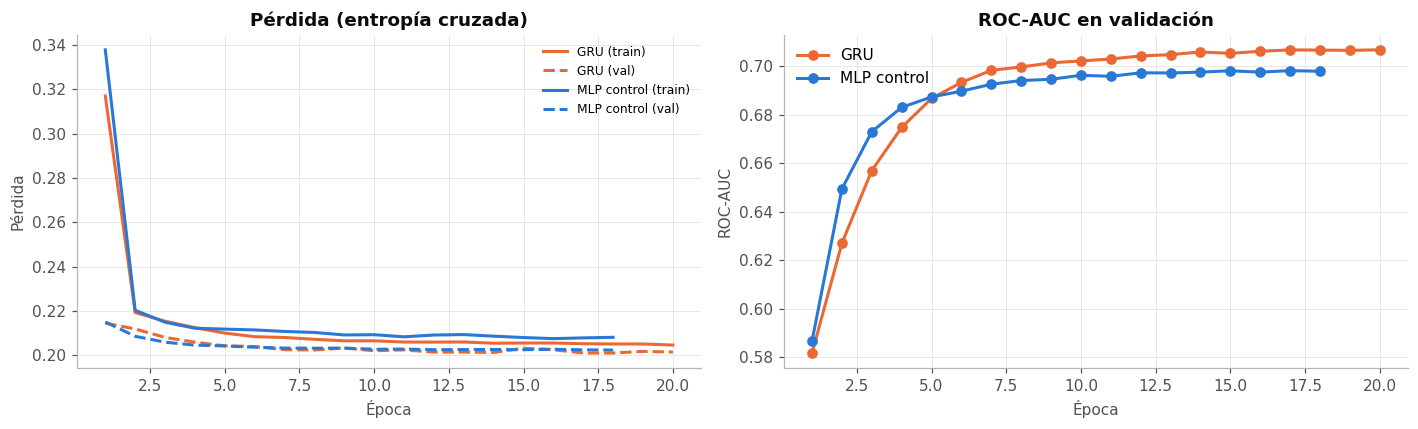

In [7]:
COLORES = {'GRU': NARANJA, 'LSTM': MAGENTA, 'MLP control': AZUL, 'Random Forest': AQUA, 'Regresión logística': GRIS}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for nombre, h in historias.items():
    axes[0].plot(h['época'], h['pérdida train'], color=COLORES[nombre], linewidth=2, label=f'{nombre} (train)')
    axes[0].plot(h['época'], h['pérdida val'], color=COLORES[nombre], linewidth=2, linestyle='--', label=f'{nombre} (val)')
    axes[1].plot(h['época'], h['ROC-AUC val'], color=COLORES[nombre], linewidth=2, marker='o', label=nombre)
axes[0].set(title='Pérdida (entropía cruzada)', xlabel='Época', ylabel='Pérdida')
axes[1].set(title='ROC-AUC en validación', xlabel='Época', ylabel='ROC-AUC')
axes[0].legend(fontsize=8); axes[1].legend()
plt.tight_layout()
plt.show()

**Resultado.** Ambas redes convergen de forma estable y **sin sobreajuste**.

- **GRU:** el ROC-AUC de validación sube de 0.582 (época 1) a **0.707 en la época 17**, y el *early stopping* se detiene en la época 20 tras tres épocas sin mejora. La pérdida de validación baja junto con la de train y nunca vuelve a subir.
- **MLP de control:** aprende más rápido al principio (en las épocas 2-5 supera a la GRU), porque recibe la información ya resumida. Pero se estanca antes, en **0.698 en la época 15**.
- **El cruce de las curvas es informativo.** La GRU necesita unas 6 épocas para aprender por sí misma a resumir la secuencia; a partir de ahí supera al control y mantiene una ventaja estable de ≈0.009 en validación.
- La pérdida de train queda ligeramente por encima de la de validación porque durante el entrenamiento el *dropout* apaga el 20% de las neuronas y en validación no. Es lo esperado y confirma que no hay memorización.
- **Costo:** ≈13 s por época para la GRU y ≈2 s para el control; 5 minutos en total en CPU.

> Esta ejecución usó `FRAC_TRAIN = 0.3`: las redes se entrenaron con **80,491 pacientes** (30% del train), mientras que el Random Forest de `03` usó los 335,380 del train completo. Se retoma en las conclusiones.

## 6. Evaluación en test
Mismas métricas que los otros cuadernos. Las probabilidades de modelos sin pesos de clase deberían estar cerca de la prevalencia real (≈5.6%).

In [8]:
Xte, Ete, yte_t = datos['test']
y_test = yte_t.numpy()
prob_test = {nombre: predecir(m, Xte, Ete) for nombre, m in modelos.items()}

def captura_top(y, p, pct=10):
    n = int(len(y) * pct / 100)
    y_ord = y[np.argsort(-p)]
    return y_ord[:n].sum() / y_ord.sum() * 100

def metricas(y, p):
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p), 'Brier': brier_score_loss(y, p),
            '% complicaciones en el top 10%': captura_top(y, p), 'Prob. media': p.mean()}

tabla_test = pd.DataFrame({nombre: metricas(y_test, p) for nombre, p in prob_test.items()}).T
print(f"Prevalencia en test: {y_test.mean():.4f}")
tabla_test.round(4)

Prevalencia en test: 0.0560


,ROC-AUC,PR-AUC,Brier,% complicaciones en el top 10%,Prob. media
GRU,0.7028,0.1252,0.0512,26.6014,0.0549
MLP control,0.6930,0.1172,0.0515,24.6861,0.0525


**Resultado.** En test, la GRU obtiene un ROC-AUC de **0.703** y un PR-AUC de **0.125** (2.2 veces la prevalencia de 0.056), frente a 0.693 y 0.117 del MLP de control. El 10% de pacientes con mayor riesgo según la GRU concentra el **26.6%** de las complicaciones de 2024, casi 2 puntos más que con el control (24.7%).

El desempeño en test es coherente con el de validación (0.707 → 0.703): la pequeña caída es la esperable, porque la época final se eligió mirando la validación. Además, la probabilidad media predicha por la GRU (5.49%) coincide casi con la prevalencia real (5.60%): **entrenada sin pesos de clase, sus probabilidades son realistas**.

## 7. ¿Importa el orden temporal?

### 7.1 GRU vs. MLP de control (bootstrap pareado)
Ambos modelos reciben la misma información; solo la GRU la ve en orden. Se remuestrea el test 500 veces y se compara el AUC de ambos **sobre los mismos pacientes**. Si el intervalo del 95% de la diferencia no incluye el 0, el orden temporal aporta.

In [9]:
def bootstrap_diferencias(y, prob_a, prob_b, n=500):
    rng = np.random.default_rng(SEED)
    filas = []
    for _ in range(n):
        b = rng.integers(0, len(y), len(y))
        filas.append({'Δ ROC-AUC': roc_auc_score(y[b], prob_a[b]) - roc_auc_score(y[b], prob_b[b]),
                      'Δ PR-AUC': average_precision_score(y[b], prob_a[b]) - average_precision_score(y[b], prob_b[b])})
    d = pd.DataFrame(filas)
    return pd.DataFrame({'Diferencia media': d.mean(), 'IC 95% inferior': d.quantile(0.025), 'IC 95% superior': d.quantile(0.975),
                         '¿Significativa?': (d.quantile(0.025) > 0) | (d.quantile(0.975) < 0)})

comparaciones = {'GRU − MLP control': ('GRU', 'MLP control')}
if 'LSTM' in prob_test:
    comparaciones.update({'LSTM − MLP control': ('LSTM', 'MLP control'), 'GRU − LSTM': ('GRU', 'LSTM')})
pd.concat({nombre: bootstrap_diferencias(y_test, prob_test[a], prob_test[b]) for nombre, (a, b) in comparaciones.items()}).round(4)

Diferencia media  IC 95% inferior  \
GRU − MLP control Δ ROC-AUC            0.0097           0.0064   
                  Δ PR-AUC             0.0079           0.0038   

                             IC 95% superior  ¿Significativa?  
GRU − MLP control Δ ROC-AUC           0.0131             True  
                  Δ PR-AUC            0.0123             True

**Resultado.** La ventaja de la GRU sobre el control es **pequeña pero estadísticamente significativa** en ambas métricas:

| Diferencia GRU − MLP control | Media | IC 95% |
|---|---|---|
| ROC-AUC | +0.0097 | [0.0064 ; 0.0131] |
| PR-AUC | +0.0079 | [0.0038 ; 0.0123] |

Ninguno de los dos intervalos incluye el 0. Como ambos modelos reciben exactamente las mismas 21 variables mensuales y las mismas 4 estáticas, y solo la GRU las ve en orden, **la diferencia se puede atribuir al orden temporal de la historia del paciente**. Para dimensionarla: es del mismo orden que la ventaja del Random Forest sobre la regresión logística (+0.013).

### 7.2 Prueba de meses desordenados
Si la GRU realmente usa el orden de los meses, al **desordenar** los meses de cada paciente en el test (misma información, otro orden) su desempeño debería caer. También se prueba invertir el orden (diciembre 2023 primero). Si el AUC casi no cambia, la red está usando la secuencia como una bolsa de meses, igual que el control.

In [10]:
rng = np.random.default_rng(SEED)
Xn = Xte.numpy()
desordenado = np.take_along_axis(Xn, np.argsort(rng.random((Xn.shape[0], N_MESES)), axis=1)[:, :, None], axis=1)
invertido = Xn[:, ::-1, :].copy()

filas = []
for nombre in [n for n in ('GRU', 'LSTM') if n in modelos]:
    m = modelos[nombre]
    for etiqueta, Xvar in [('Orden real', Xn), ('Meses desordenados', desordenado), ('Orden invertido', invertido)]:
        p = predecir(m, torch.from_numpy(np.ascontiguousarray(Xvar)), Ete)
        filas.append({'Modelo': nombre, 'Entrada': etiqueta, 'ROC-AUC': roc_auc_score(y_test, p),
                      'PR-AUC': average_precision_score(y_test, p)})
prueba_orden = pd.DataFrame(filas).set_index(['Modelo', 'Entrada'])
prueba_orden.round(4)

ROC-AUC  PR-AUC
Modelo Entrada                            
GRU    Orden real           0.7028  0.1252
       Meses desordenados   0.6959  0.1199
       Orden invertido      0.6930  0.1174

**Resultado.** La GRU **depende del orden de los meses**:

| Entrada en test | ROC-AUC | Cambio |
|---|---|---|
| Orden real | 0.7028 | — |
| Meses desordenados al azar | 0.6959 | −0.0069 |
| Orden invertido (dic 2023 primero) | 0.6930 | −0.0098 |

El dato más revelador es el del orden invertido: con los meses al revés, la GRU cae a **exactamente el nivel del MLP de control (0.6930)**. Al invertir la secuencia, los meses más recientes quedan al principio, donde la red espera información antigua y les da poco peso; pierde así toda su ventaja. Con los meses desordenados al azar conserva una parte, porque algunos meses recientes caen por casualidad al final.

Las dos pruebas apuntan en la misma dirección que el bootstrap de 7.1: la red no usa la secuencia como una "bolsa de meses", sino que **aprendió que lo más reciente importa más**.

## 8. ¿Qué meses importan? (importancia por trimestre)
Para cada trimestre, se **intercambian al azar** sus meses entre pacientes del test (se rompe la relación de ese trimestre con `y` sin cambiar su distribución) y se mide cuánto cae el ROC-AUC de la GRU. Es la importancia por permutación, aplicada a bloques de tiempo. Se repite 3 veces por trimestre.

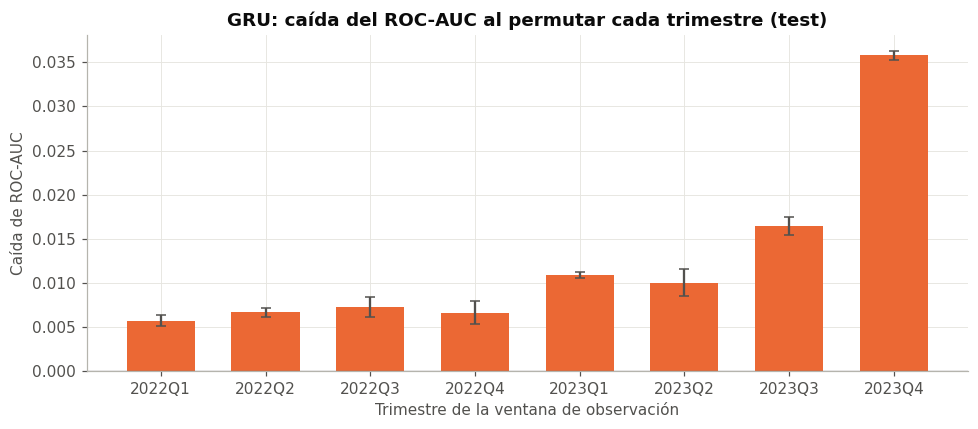

,Trimestre,Caída de ROC-AUC,Desv.
0,2022Q1,0.0057,0.0006
1,2022Q2,0.0067,0.0005
2,2022Q3,0.0073,0.0012
3,2022Q4,0.0066,0.0013
4,2023Q1,0.0109,0.0004
5,2023Q2,0.0100,0.0015
6,2023Q3,0.0165,0.0010
7,2023Q4,0.0358,0.0005


In [11]:
m = modelos['GRU']
auc_base = roc_auc_score(y_test, prob_test['GRU'])
trimestres = pd.period_range('2022Q1', periods=N_MESES // 3, freq='Q').astype(str)
filas = []
for t, nombre_t in enumerate(trimestres):
    caidas = []
    for r in range(3):
        perm = np.random.default_rng(SEED + r).permutation(len(Xn))
        Xp = Xn.copy()
        Xp[:, 3 * t:3 * t + 3, :] = Xn[perm, 3 * t:3 * t + 3, :]
        caidas.append(auc_base - roc_auc_score(y_test, predecir(m, torch.from_numpy(Xp), Ete)))
    filas.append({'Trimestre': nombre_t, 'Caída de ROC-AUC': np.mean(caidas), 'Desv.': np.std(caidas)})
imp_trim = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(imp_trim['Trimestre'], imp_trim['Caída de ROC-AUC'], yerr=imp_trim['Desv.'], color=NARANJA, width=0.65,
       error_kw={'ecolor': TEXTO_2, 'capsize': 3})
ax.axhline(0, color=TEXTO_2, linewidth=0.8)
ax.set(title='GRU: caída del ROC-AUC al permutar cada trimestre (test)', xlabel='Trimestre de la ventana de observación',
       ylabel='Caída de ROC-AUC')
plt.tight_layout()
plt.show()
imp_trim.round(4)

**Resultado.** La importancia crece de forma casi monótona hacia el final de la ventana de observación:

- Los cuatro trimestres de 2022 aportan poco y de forma pareja (caídas de 0.006 a 0.007).
- El primer semestre de 2023 aporta algo más (≈0.010-0.011).
- **2023Q3 (0.017) y sobre todo 2023Q4 (0.036)** dominan. El último trimestre por sí solo pesa más del doble que el anterior y entre 5 y 6 veces más que cualquier trimestre de 2022. Los dos últimos trimestres explican el **53%** de la suma de todas las caídas.

**Interpretación clínica.** Lo que le ocurrió al paciente en los 3-6 meses previos a 2024 es lo que más anticipa una complicación en 2024. Es coherente con la curva de emergencias de `04_secuencias`, que se separa entre grupos justamente en el segundo semestre de 2023. La historia de 2022 no es irrelevante (ningún trimestre tiene importancia cero), pero su aporte es secundario.

**Implicancia práctica.** Los modelos tabulares de `02` y `03` resumen los 24 meses con el mismo peso. Agregarles variables de **recencia** (por ejemplo, emergencias y atenciones de los últimos 3 y 6 meses, o la tendencia de la presión en 2023 frente a 2022) probablemente recuperaría parte de esta ventaja sin necesidad de una red recurrente.

*Nota metodológica:* la importancia por permutación mide el aporte de cada trimestre manteniendo los demás. Como los meses vecinos están correlacionados (un paciente activo en 2023Q3 suele estarlo en 2023Q4), parte del aporte se reparte entre trimestres contiguos.

## 9. Comparación final con los modelos tabulares
Si `03_random_forest.ipynb` guardó sus probabilidades de test (`predicciones_test_rf_rl.csv`), se comparan **sobre los mismos pacientes**, con bootstrap pareado. Si no, se leen las métricas de `resultados_random_forest.csv`.

,ROC-AUC,PR-AUC,Brier,% complicaciones en el top 10%,Prob. media
Random Forest,0.7050,0.1241,0.0512,26.3247,0.0562
GRU,0.7028,0.1252,0.0512,26.6014,0.0549
MLP control,0.6930,0.1172,0.0515,24.6861,0.0525
Regresión logística,0.6918,0.1177,0.0515,24.7712,0.0561


,Diferencia media,IC 95% inferior,IC 95% superior,¿Significativa?
GRU − Random Forest,,,,
Δ ROC-AUC,-0.0024,-0.0064,0.0012,False
Δ PR-AUC,0.0011,-0.0029,0.0052,False


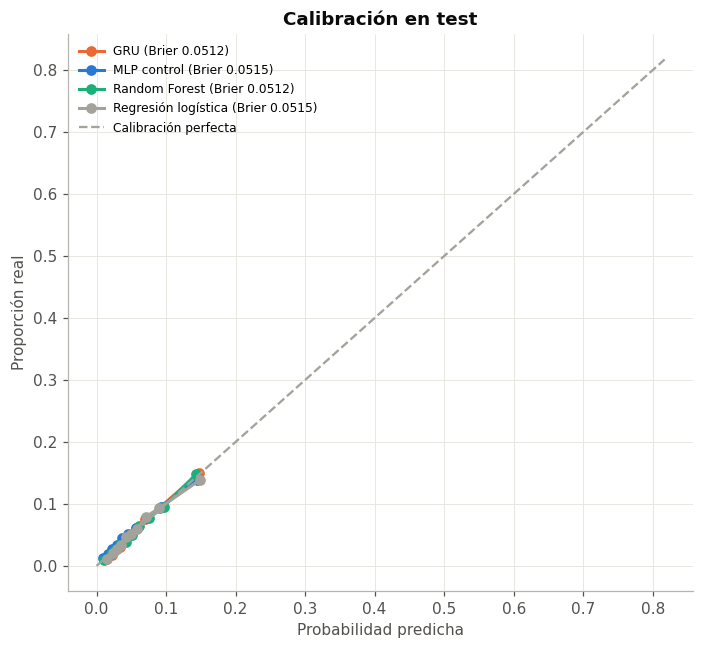

In [12]:
archivo_pred = RUTA / 'predicciones_test_rf_rl.csv'
pacientes_test = meta['paciente'].values[idx['test']]
if archivo_pred.exists():
    pred = pd.read_csv(archivo_pred).set_index('paciente').reindex(pacientes_test)
    assert pred['prob_rf'].notna().all(), "Los pacientes de test no coinciden con los de 03_random_forest"
    assert np.array_equal(pred['y'].values.astype(int), y_test.astype(int)), "El y de test no coincide"
    prob_test['Random Forest'] = pred['prob_rf'].values
    prob_test['Regresión logística'] = pred['prob_rl_sin_pesos'].values
    final = pd.DataFrame({nombre: metricas(y_test, p) for nombre, p in prob_test.items()}).T.sort_values('ROC-AUC', ascending=False)
    display(final.round(4))
    display(bootstrap_diferencias(y_test, prob_test['GRU'], prob_test['Random Forest']).round(4).rename_axis('GRU − Random Forest'))
else:
    print("No se encontró predicciones_test_rf_rl.csv: vuelve a ejecutar 03_random_forest.ipynb (versión actual) para comparar paciente a paciente.")
    previos = pd.read_csv(RUTA / 'resultados_random_forest.csv', index_col=0)[['ROC-AUC', 'PR-AUC', 'Brier']]
    final = pd.concat([tabla_test[['ROC-AUC', 'PR-AUC', 'Brier']], previos]).sort_values('ROC-AUC', ascending=False)
    display(final.round(4))

fig, ax = plt.subplots(figsize=(6.5, 6))
for nombre, p in prob_test.items():
    real, predicha = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    ax.plot(predicha, real, marker='o', linewidth=2, color=COLORES.get(nombre, TEXTO_2), label=f'{nombre} (Brier {brier_score_loss(y_test, p):.4f})')
lim = max(p.max() for p in prob_test.values())
ax.plot([0, lim], [0, lim], color=GRIS, linestyle='--', label='Calibración perfecta')
ax.set(title='Calibración en test', xlabel='Probabilidad predicha', ylabel='Proporción real')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Resultado.** Comparación sobre los **mismos 83,846 pacientes de test**:

| Modelo | ROC-AUC | PR-AUC | Brier | % complicaciones en el top 10% |
|---|---|---|---|---|
| Random Forest | **0.7050** | 0.1241 | 0.0512 | 26.3% |
| GRU | 0.7028 | **0.1252** | 0.0512 | **26.6%** |
| MLP de control | 0.6930 | 0.1172 | 0.0515 | 24.7% |
| Regresión logística (sin pesos) | 0.6918 | 0.1177 | 0.0515 | 24.8% |

- **La GRU y el Random Forest empatan.** La diferencia es de −0.0024 en ROC-AUC (IC 95%: −0.0064 a +0.0012) y de +0.0011 en PR-AUC (IC 95%: −0.0029 a +0.0052). Ambos intervalos incluyen el 0, así que no hay un ganador estadístico. En PR-AUC y en captura del top 10%, la GRU incluso queda ligeramente por encima.
- **El empate tiene mérito para la GRU.** Usa solo 21 variables mensuales y 4 estáticas, frente a las 34 del bosque, que incluyen gasto, `prop_capita`, presión máxima o presión de pulso. Además, se entrenó con el **30% del train** (80,491 pacientes frente a 335,380).
- **Los dos modelos llegan al mismo techo por caminos distintos.** El bosque combina de forma no lineal muchas variables agregadas; la GRU explota la dinámica temporal. Que dos enfoques tan diferentes coincidan en ≈0.70 sugiere que **el límite lo pone la información disponible** (datos administrativos sin laboratorio, como creatinina o HbA1c), no el algoritmo.
- **Los cuatro modelos están bien calibrados.** Todos quedan sobre la diagonal, con Brier entre 0.0512 y 0.0515 y riesgos predichos de hasta ≈15%. Confirma lo visto en `03`: sin pesos de clase, tanto los modelos tabulares como las redes producen probabilidades interpretables.

## 10. Guardar

In [13]:
tabla_test.to_csv(RUTA / 'resultados_gru.csv')
pd.DataFrame({'paciente': pacientes_test, 'y': y_test.astype(int), **{f'prob_{k.lower().replace(" ", "_")}': v for k, v in prob_test.items()}}) \
  .to_csv(RUTA / 'predicciones_test_gru.csv', index=False)
for nombre, m in modelos.items():
    torch.save(m.state_dict(), RUTA / f"modelo_{nombre.lower().replace(' ', '_')}.pt")
print("Guardado en:", RUTA)

Guardado en: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\data\processed


## 11. Conclusiones

1. **El orden temporal aporta información, y la red la aprovecha.** Con las mismas variables, la GRU supera al MLP que las recibe sin orden en +0.0097 de ROC-AUC (IC 95%: 0.0064-0.0131) y +0.0079 de PR-AUC, ambas diferencias significativas. Al invertir el orden de los meses, la GRU cae exactamente al nivel del control (0.6930): toda su ventaja proviene de la secuencia.

2. **Lo reciente pesa más.** El último trimestre de 2023 es, por lejos, el periodo más importante (caída de 0.036 en el ROC-AUC al permutarlo, frente a 0.006-0.007 de cada trimestre de 2022), y los dos últimos trimestres explican el 53% de la importancia total. Clínicamente, coincide con lo observado en `04_secuencias`: los pacientes que se complicarán aumentan sus emergencias de forma acelerada en el segundo semestre de 2023 (razón frente a los que no se complican: de 1.36 a 1.64).

3. **La GRU alcanza al mejor modelo tabular.** ROC-AUC de 0.703 frente a 0.705 del Random Forest (diferencia no significativa) y mejor PR-AUC (0.125 frente a 0.124) y captura del top 10% (26.6% frente a 26.3%). Lo logra con menos variables y con el 30% de los pacientes de entrenamiento.

4. **Probabilidades confiables.** Entrenada sin pesos de clase, la GRU predice una probabilidad media de 5.49% frente a una prevalencia real de 5.60%, y su curva de calibración sigue la diagonal (Brier 0.0512, igual al del bosque).

5. **El techo está en los datos, no en el modelo.** Cuatro modelos muy distintos (regresión logística, MLP, Random Forest, GRU) quedan entre 0.69 y 0.71 de ROC-AUC. Con datos administrativos, sin resultados de laboratorio ni información sobre adherencia al tratamiento, ese parece ser el límite alcanzable para predecir complicaciones a un año.

6. **Costo y explicabilidad.** La GRU entrenó en 5 minutos en CPU, pero exige construir el tensor mensual (`04_secuencias`) y es más difícil de explicar que un bosque. Su principal valor en este proyecto no es superar al Random Forest, sino **demostrar con evidencia que la dinámica reciente del paciente contiene señal predictiva** que los resúmenes de dos años diluyen.

### Limitaciones
- **Entrenamiento con el 30% del train** (`FRAC_TRAIN = 0.3`); con el train completo el desempeño de la GRU podría mejorar.
- **Solo se entrenó la GRU.** La LSTM queda pendiente (`ENTRENAR_LSTM = True`).
- **Granularidad mensual y 21 variables por mes**, sin códigos individuales de medicamentos (por ejemplo, antihipertensivos) ni el detalle de cada visita.
- **Sesgo de detección**, compartido con los demás modelos: el aumento de emergencias y atenciones antes del evento refleja en parte deterioro clínico y en parte mayor contacto con el sistema, que facilita que el diagnóstico se registre.
- **Sin validación temporal propia.** `06_robustez` mostró que los modelos tabulares se mantienen de un año a otro (pierden 0.011 de AUC); la GRU no se evaluó en ese diseño.

### Trabajo futuro
1. Reentrenar con `FRAC_TRAIN = None` y probar la LSTM.
2.**Hecho en `07_boosting_ensamble`:** el promedio RF + GRU llega a 0.710 (+0.005 sobre el RF, significativo) y el promedio RF + boosting + GRU, a **0.712**, el mejor resultado del proyecto. La GRU es la pieza más distinta de los modelos tabulares (correlación 0.88 con el RF) y por eso la que más aporta al ensamble.
3. Agregar **variables de recencia** (últimos 3 y 6 meses) a los modelos tabulares, para comprobar si recuperan la ventaja de la GRU con un modelo más simple.
4. Un mecanismo de **atención** sobre los meses, al estilo de RETAIN (Choi et al., 2016), para identificar qué meses y qué variables explican cada predicción individual.

### Referencias
- Cho, K. et al. (2014). Learning phrase representations using RNN encoder-decoder for statistical machine translation. *EMNLP*.
- Hochreiter, S. y Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735-1780.
- Choi, E. et al. (2016). RETAIN: An interpretable predictive model for healthcare using reverse time attention mechanism. *NeurIPS*.
- Zhao, J. et al. (2019). Learning from longitudinal data in electronic health record and genetic data to improve cardiovascular event prediction. *Scientific Reports*, 9, 717.